In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (1).png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (1)_mask.png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (10).png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (10)_mask.png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (100).png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (100)_mask.png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (100)_mask_1.png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (101).png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/

*  # Importing PyTorch and checking its version 

In [3]:
import torch

print( "PyTorch version is: ", torch.__version__)

PyTorch version is:  2.11.0+cu130


# cuda means? CUDA stands for Compute Unified Device Architecture.
#CUDA is a technology/platform developed by NVIDIA that allows software like PyTorch to use NVIDIA GPUs.

In [4]:
print(" CUDA AVAILABLE: ", torch.cuda.is_available())

if torch.cuda.is_available():
    print ("GPU: ", torch.cuda.get_device_name(0))

else:
    print("Running in device")

 CUDA AVAILABLE:  True
GPU:  Tesla T4


# Import data science and visualization libraries

In [5]:

import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

print("All libraries imported successfully!")


All libraries imported successfully!


# PIL-> open image and Path-> navigate the dataset folder

# Checking correct dataset with subfolder

In [6]:

import os

for dirname, subdirs, filenames in os.walk('/kaggle/input'):
    print("Folder:", dirname)
    print("Subfolders:", subdirs)
    print("Number of files:", len(filenames))


Folder: /kaggle/input
Subfolders: ['datasets']
Number of files: 0
Folder: /kaggle/input/datasets
Subfolders: ['aryashah2k']
Number of files: 0
Folder: /kaggle/input/datasets/aryashah2k
Subfolders: ['breast-ultrasound-images-dataset']
Number of files: 0
Folder: /kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset
Subfolders: ['Dataset_BUSI_with_GT']
Number of files: 0
Folder: /kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT
Subfolders: ['benign', 'malignant', 'normal']
Number of files: 0
Folder: /kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign
Subfolders: []
Number of files: 891
Folder: /kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/malignant
Subfolders: []
Number of files: 421
Folder: /kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/normal
Subfolders: []
Number of files: 266


# Count image and mask

In [7]:

from pathlib import Path

root = Path(
    "/kaggle/input/datasets/aryashah2k/"
    "breast-ultrasound-images-dataset/"
    "Dataset_BUSI_with_GT"
)

print("Dataset exists:", root.exists())


Dataset exists: True


In [8]:

CLASSES = ["normal", "benign", "malignant"]

for category in CLASSES:

    images = [
        p for p in (root / category).glob("*.png")
        if "_mask" not in p.name.lower()
    ]

    masks = [
        p for p in (root / category).glob("*.png")
        if "_mask" in p.name.lower()
    ]

    print(f"\nCategory: {category}")
    print("Original images:", len(images))
    print("Mask files:", len(masks))
    print("Total files:", len(images) + len(masks))



Category: normal
Original images: 133
Mask files: 133
Total files: 266

Category: benign
Original images: 437
Mask files: 454
Total files: 891

Category: malignant
Original images: 210
Mask files: 211
Total files: 421


# Plot random three images from each categories

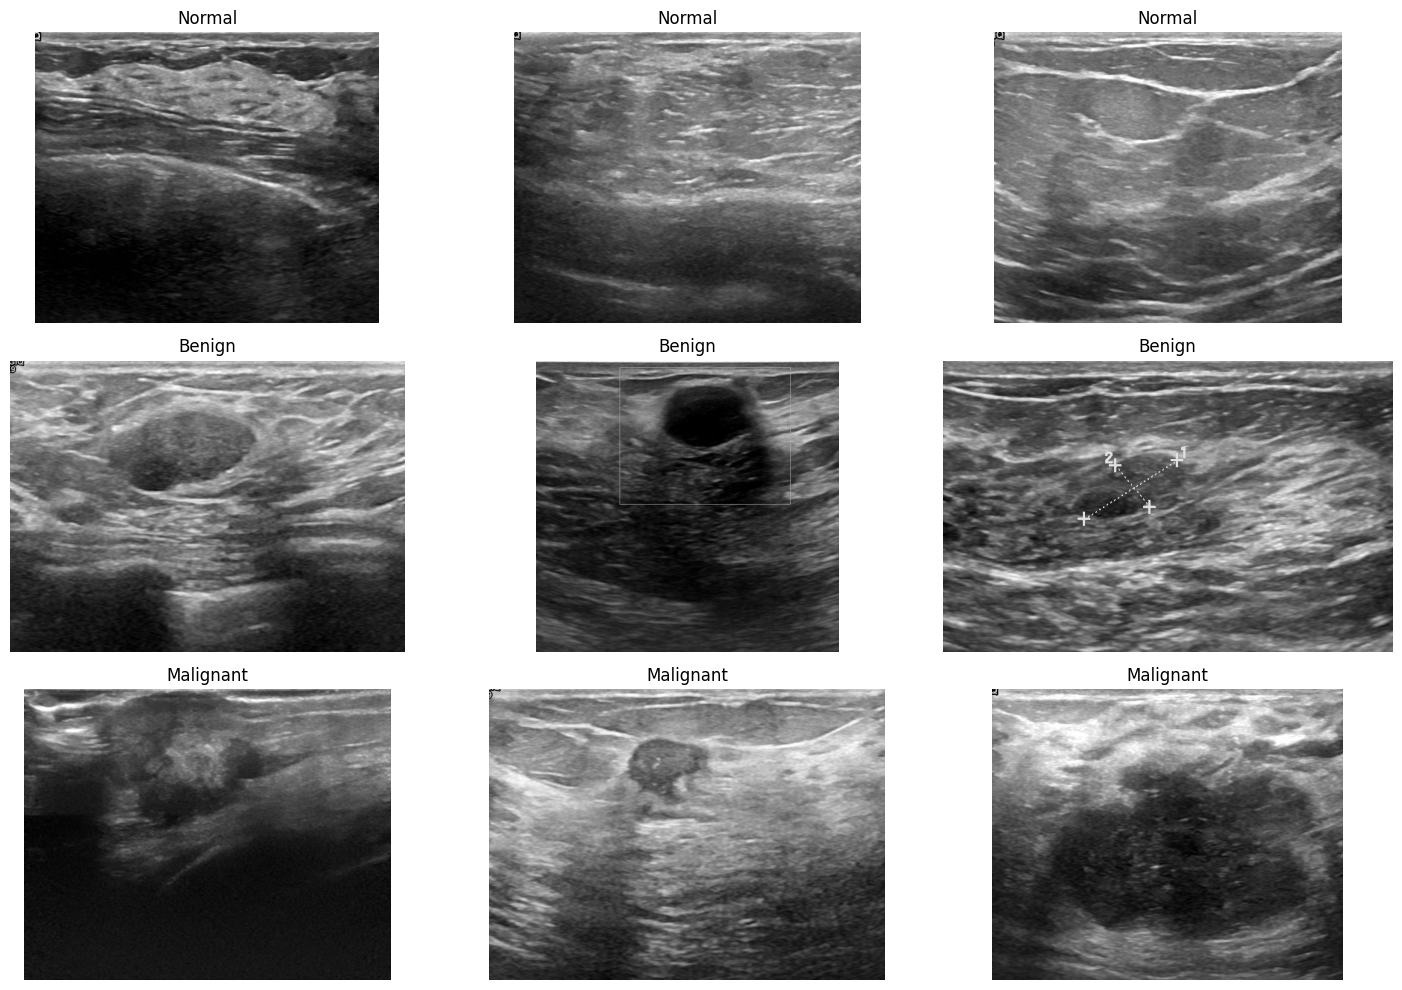

In [9]:

import matplotlib.pyplot as plt
from PIL import Image
import random

plt.figure(figsize=(15, 10))

for row, category in enumerate(CLASSES):

    image_paths = [
        p for p in (root / category).glob("*.png")
        if "_mask" not in p.name.lower()
    ]

    selected_images = random.sample(
        image_paths,
        min(3, len(image_paths))
    )

    for col, image_path in enumerate(selected_images):

        img = Image.open(image_path).convert("L")

        plt.subplot(3, 3, row * 3 + col + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"{category.capitalize()}")
        plt.axis("off")

plt.tight_layout()
plt.show()


# Image count and bar chart

       Class  Number of Images
0     normal               133
1     benign               437
2  malignant               210


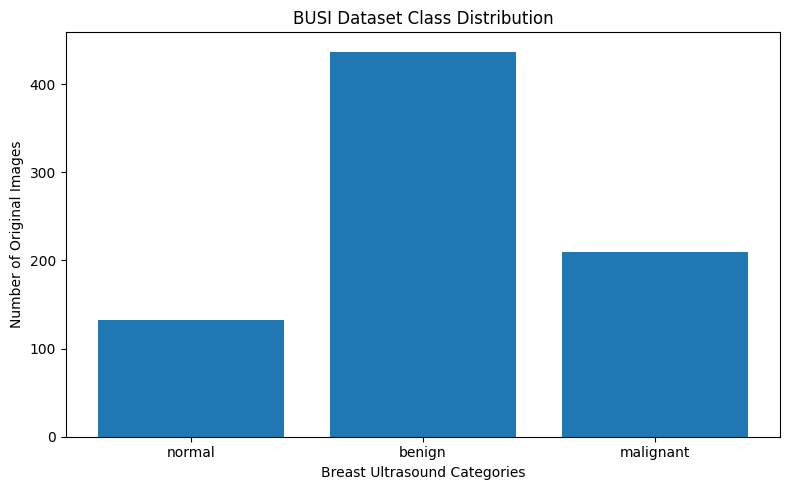

In [10]:

import pandas as pd
import matplotlib.pyplot as plt

class_counts = {}

for category in CLASSES:

    images = [
        p for p in (root / category).glob("*.png")
        if "_mask" not in p.name.lower()
    ]

    class_counts[category] = len(images)

df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Number of Images"]
)

print(df)

plt.figure(figsize=(8, 5))

plt.bar(
    df["Class"],
    df["Number of Images"]
)

plt.title("BUSI Dataset Class Distribution")
plt.xlabel("Breast Ultrasound Categories")
plt.ylabel("Number of Original Images")

plt.tight_layout()
plt.show()
